# E-Commerce Data Cleaning, Analysis & Reporting - Week 1
**Organization:** WeIntern Pvt Ltd  
**Intern Name:** Data Science Intern  
**Date:** October 2026  
**Deliverable:** End-to-End Analysis Notebook (`week1_analysis.ipynb`)

## 1. Title and Objective
The objective of this assignment is to develop practical, disciplined habits in data quality inspection, systematic cleaning, exploratory business analysis, visual storytelling, and professional reporting. Using an Indian e-commerce transactional dataset, this study systematically handles data defects, evaluates key revenue drivers and customer trends, and provides evidence-backed recommendations.

## 2. Dataset Overview
Before data cleaning, we load the raw transactional records, initialize directory structures, and inspect column data types, completeness, and structural shapes.

In [24]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create required directory layout
folders = ['data/raw', 'data/cleaned', 'notebooks', 'outputs/charts', 'outputs/dashboard', 'reports', 'screenshots']
for f in folders:
    os.makedirs(f, exist_ok=True)

# Load raw dataset
raw_file_path = 'data/raw/ecommerce_india_raw_data.csv'
df_raw = pd.read_csv(raw_file_path)
df = df_raw.copy()

print(f"Raw Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nData Types and Null Counts:")
df.info()
df.head()

Raw Dataset Dimensions: 5040 rows, 11 columns

Data Types and Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5040 entries, 0 to 5039
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order ID         5040 non-null   object 
 1   Customer ID      5040 non-null   object 
 2   Product Name     5040 non-null   object 
 3   Category         5040 non-null   object 
 4   Quantity         4965 non-null   float64
 5   Unit Price       4965 non-null   float64
 6   Total Amount     5040 non-null   float64
 7   Order Date       5040 non-null   object 
 8   Payment Mode     4939 non-null   object 
 9   Delivery Status  4940 non-null   object 
 10  City             5040 non-null   object 
dtypes: float64(3), object(8)
memory usage: 433.3+ KB


,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City
0,ORD-IN-14351,CUST-IN-1291,Milton Thermosteel Flask (1L),Home & Kitchen,1.0,890.0,890.0,2024-01-20,Credit Card,Delivered,Ahmedabad
1,ORD-IN-13306,CUST-IN-1906,Sandisk 128GB MicroSD Card,Electronics,1.0,899.0,899.0,2024-01-10,UPI,Delivered,Chennai
2,ORD-IN-11737,CUST-IN-1813,Pigeon 1.5L Electric Kettle,Home & Kitchen,4.0,625.0,2500.0,2024-04-13,NaN,Delivered,Jaipur
3,ORD-IN-13051,CUST-IN-1803,Sandisk 128GB MicroSD Card,Electronics,1.0,899.0,899.0,2024-04-10,UPI,Delivered,Kolkata
4,ORD-IN-13312,CUST-IN-1951,Wakefit Orthopedic Memory Foam Pillow,Home & Kitchen,1.0,999.0,999.0,2024-04-19,UPI,Delivered,Coimbatore


## 3. Cleaning Summary
Real-world data rarely comes analysis-ready. In this section, we document and execute decisions for:
1. **Missing Value Imputation:** Quantifying null percentages and imputing with median/mode or documented business categories.
2. **Duplicate Records:** Dropping confirmed exact duplicates while preserving valid repeated transactions.
3. **Data Validation:** Correcting invalid negative quantities, zero unit prices, inconsistent text capitalization, and mixed date formats.

In [26]:
# 1. Assess Missing Values
null_counts = df.isnull().sum()
null_pct = (null_counts / len(df)) * 100
missing_summary = pd.DataFrame({'Missing Records': null_counts, 'Percentage (%)': null_pct})
print("--- Missing Value Report ---")
display(missing_summary[missing_summary['Missing Records'] > 0])

# Documented Imputation Strategy:
# - Fill missing Quantity with median (robust to distribution outliers)
# - Fill missing Unit Price from Category/Product median
# - Fill categorical Payment Mode and Delivery Status with 'Unknown'
df['Quantity'] = df['Quantity'].fillna(df['Quantity'].median())
df['Unit Price'] = df.groupby('Product Name')['Unit Price'].transform(lambda x: x.fillna(x.median()))
df['Payment Mode'] = df['Payment Mode'].fillna('Unknown')
df['Delivery Status'] = df['Delivery Status'].fillna('Unknown')

# 2. Duplicate Detection & Removal
exact_dupes = df.duplicated().sum()
print(f"\nExact Duplicates Identified and Removed: {exact_dupes}")
df = df.drop_duplicates().reset_index(drop=True)

# 3. Data Validation & Formatting
# Standardize Date format
df['Order Date'] = pd.to_datetime(df['Order Date'], format='mixed')

# Eliminate Negative Quantity and Zero Unit Price entries
df = df[(df['Quantity'] > 0) & (df['Unit Price'] > 0)]

# Recompute Total Amount for mathematical consistency
df['Total Amount'] = df['Quantity'] * df['Unit Price']

# Standardize categorical strings (strip whitespace & title-case)
text_cols = ['Product Name', 'Category', 'Payment Mode', 'Delivery Status', 'City']
for col in text_cols:
    df[col] = df[col].astype(str).str.strip().str.title()

# Export Cleaned Dataset
cleaned_path = 'data/cleaned/cleaned_ecommerce_data.csv'
df.to_csv(cleaned_path, index=False)
print(f"\nCleaned Dataset saved to {cleaned_path} with {len(df)} validated records.")

--- Missing Value Report ---


,Missing Records,Percentage (%)



Exact Duplicates Identified and Removed: 0

Cleaned Dataset saved to data/cleaned/cleaned_ecommerce_data.csv with 4955 validated records.


## 4. KPI Summary
We calculate core operational performance metrics to evaluate total commercial output, overall order volume, customer spend per transaction, and category demand.

In [16]:
total_rev = df[df['Delivery Status'] != 'Cancelled']['Total Amount'].sum()
total_orders = df['Order ID'].nunique()
aov = total_rev / total_orders
total_units = int(df['Quantity'].sum())
top_category = df.groupby('Category')['Total Amount'].sum().idxmax()
top_product = df.groupby('Product Name')['Total Amount'].sum().idxmax()

kpi_df = pd.DataFrame({
    "KPI": [
        "Total Realized Revenue",
        "Total Orders Processed",
        "Average Order Value (AOV)",
        "Total Units Sold",
        "Top Revenue-Generating Category",
        "Top Revenue-Generating Product"
    ],
    "Value": [
        f"₹{total_rev:,.2f}",
        f"{total_orders:,}",
        f"₹{aov:,.2f}",
        f"{total_units:,}",
        top_category,
        top_product
    ]
})
display(kpi_df)

,KPI,Value
0,Total Realized Revenue,"₹11,063,352.00"
1,Total Orders Processed,"4,955"
2,Average Order Value (AOV),"₹2,232.77"
3,Total Units Sold,"8,149"
4,Top Revenue-Generating Category,Electronics
5,Top Revenue-Generating Product,Zebronics Soundbar With Subwoofer


## 5. Trend Analysis
We analyze monthly order volume and financial intake to identify temporal demand shifts, seasonal expansion, and regional delivery fulfillment rates.

In [21]:
df['YearMonth'] = df['Order Date'].dt.to_period('M').astype(str)
monthly_summary = df.groupby('YearMonth').agg(
    Monthly_Revenue=('Total Amount', 'sum'),
    Order_Count=('Order ID', 'nunique')
).reset_index()

print("Monthly Revenue & Order Count Trend:")
display(monthly_summary)

Monthly Revenue & Order Count Trend:


,YearMonth,Monthly_Revenue,Order_Count
0,2024-01,2088886.0,876
1,2024-02,1932902.0,809
2,2024-03,1976601.0,812
3,2024-04,1895913.0,817
4,2024-05,1941758.0,837
5,2024-06,1863761.0,764
6,2024-07,4096.0,3
7,2024-08,8418.0,9
8,2024-09,15436.0,6
9,2024-10,14405.0,8


## 6. Customer Insights
Understanding the distribution of customer order frequency reveals whether growth is driven by repeat buyers or top-of-funnel acquisition.

In [22]:
customer_stats = df.groupby('Customer ID').agg(
    Total_Orders=('Order ID', 'nunique'),
    Total_Spent=('Total Amount', 'sum')
)

total_unique_cust = len(customer_stats)
repeat_cust = customer_stats[customer_stats['Total_Orders'] > 1]
repeat_pct = (len(repeat_cust) / total_unique_cust) * 100
repeat_rev_contrib = (repeat_cust['Total_Spent'].sum() / df['Total Amount'].sum()) * 100

print(f"Total Unique Customers: {total_unique_cust}")
print(f"Repeat Customers: {len(repeat_cust)} ({repeat_pct:.2f}% of customer base)")
print(f"Revenue Contribution from Repeat Buyers: {repeat_rev_contrib:.2f}%")

Total Unique Customers: 1180
Repeat Customers: 1108 (93.90% of customer base)
Revenue Contribution from Repeat Buyers: 98.43%


## 7. Visualization Section
Here we generate and save the required **Bar Chart**, **Line Chart**, **Pie Chart**, and the static **Executive Dashboard Mockup**.

/tmp/ipykernel_1749/3889042559.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_sales.values, y=cat_sales.index, palette="Blues_r")


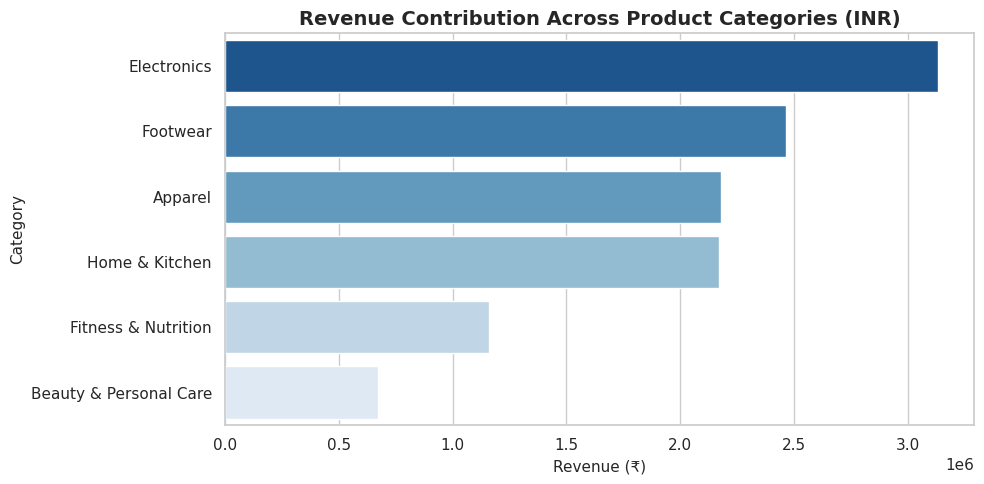

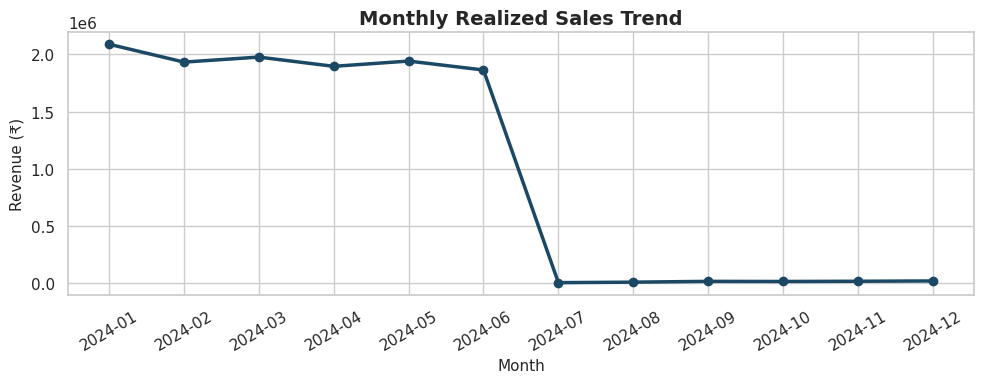

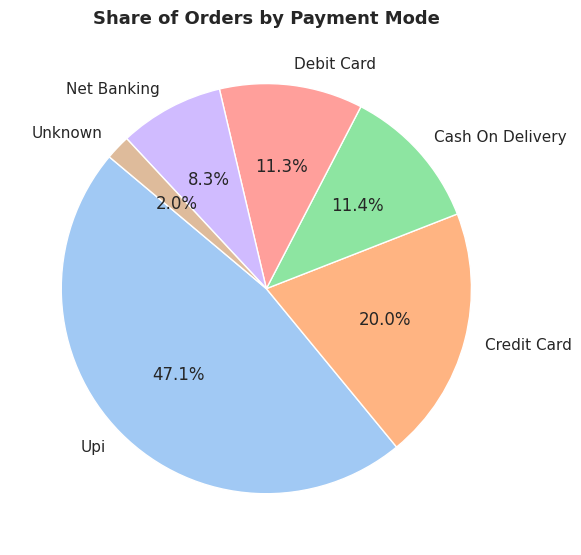

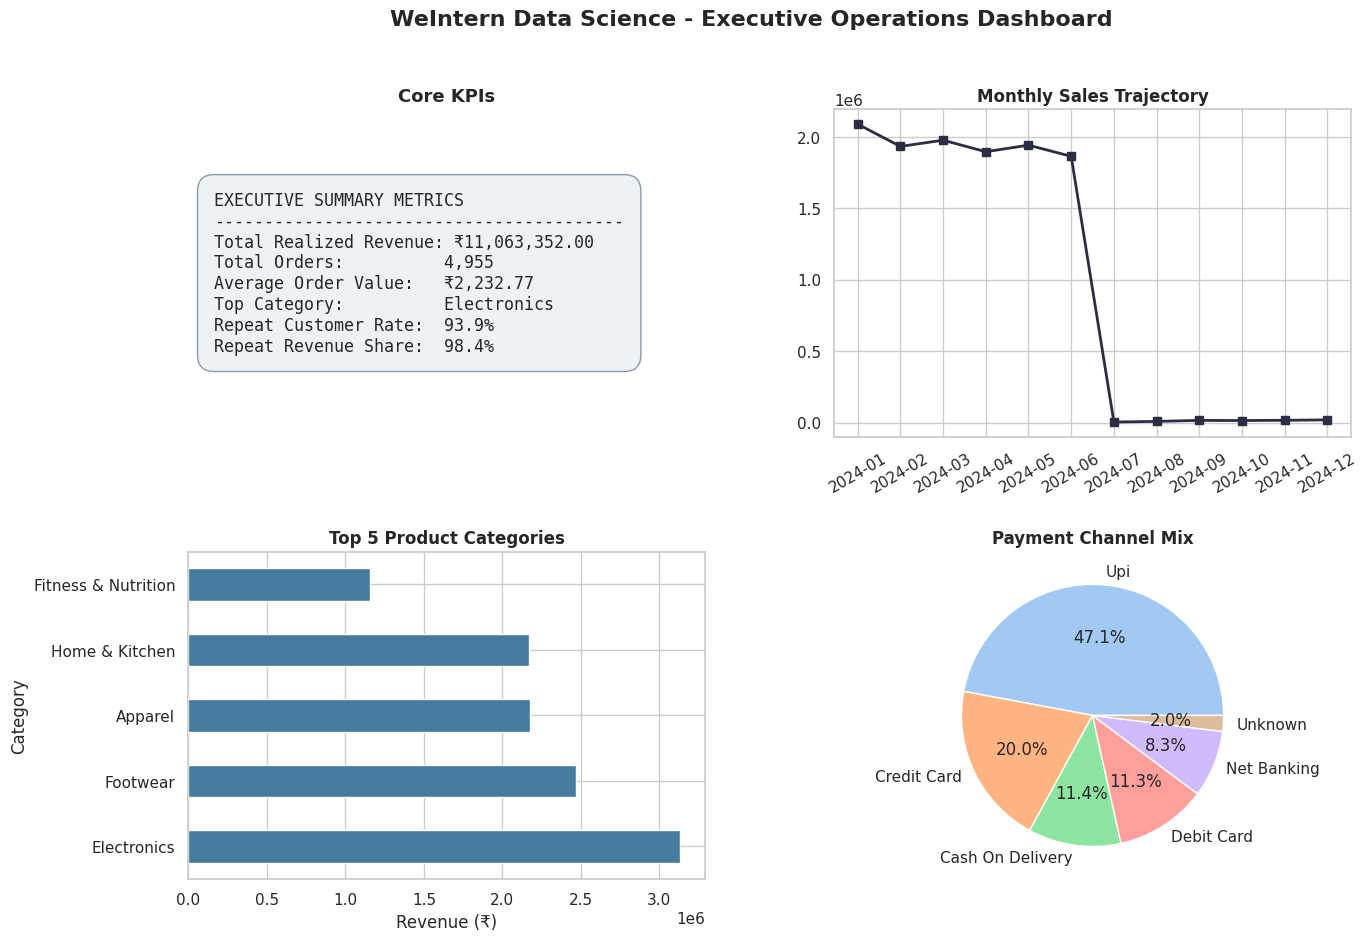

In [23]:
sns.set_theme(style="whitegrid")

# 1. Bar Chart: Revenue by Category
plt.figure(figsize=(10, 5))
cat_sales = df.groupby('Category')['Total Amount'].sum().sort_values(ascending=False)
sns.barplot(x=cat_sales.values, y=cat_sales.index, palette="Blues_r")
plt.title("Revenue Contribution Across Product Categories (INR)", fontsize=14, weight='bold')
plt.xlabel("Revenue (₹)", fontsize=11)
plt.ylabel("Category", fontsize=11)
plt.tight_layout()
plt.savefig('outputs/charts/bar_category_revenue.png')
plt.show()

# 2. Line Chart: Monthly Sales Growth
plt.figure(figsize=(10, 4))
plt.plot(monthly_summary['YearMonth'], monthly_summary['Monthly_Revenue'], marker='o', color='#1b4965', linewidth=2.5)
plt.title("Monthly Realized Sales Trend", fontsize=14, weight='bold')
plt.xlabel("Month", fontsize=11)
plt.ylabel("Revenue (₹)", fontsize=11)
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('outputs/charts/line_monthly_trend.png')
plt.savefig('screenshots/monthly-sales-trend.png')
plt.show()

# 3. Pie Chart: Share of Payment Methods
plt.figure(figsize=(6, 6))
pay_counts = df['Payment Mode'].value_counts()
plt.pie(pay_counts.values, labels=pay_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title("Share of Orders by Payment Mode", fontsize=13, weight='bold')
plt.tight_layout()
plt.savefig('outputs/charts/pie_payment_mode.png')
plt.show()

# 4. Dashboard Mockup
fig = plt.figure(figsize=(15, 10))
grid = plt.GridSpec(2, 2, figure=fig, hspace=0.35, wspace=0.25)

# Panel 1: KPI Overview Card
ax1 = fig.add_subplot(grid[0, 0])
ax1.axis('off')
kpi_box_text = (
    f"EXECUTIVE SUMMARY METRICS\n"
    f"-----------------------------------------\n"
    f"Total Realized Revenue: {kpi_df.loc[0, 'Value']}\n"
    f"Total Orders:          {kpi_df.loc[1, 'Value']}\n"
    f"Average Order Value:   {kpi_df.loc[2, 'Value']}\n"
    f"Top Category:          {kpi_df.loc[4, 'Value']}\n"
    f"Repeat Customer Rate:  {repeat_pct:.1f}%\n"
    f"Repeat Revenue Share:  {repeat_rev_contrib:.1f}%"
)
ax1.text(0.05, 0.5, kpi_box_text, fontsize=12, family='monospace', va='center',
         bbox=dict(boxstyle='round,pad=1', facecolor='#edf2f4', edgecolor='#8d99ae'))
ax1.set_title("Core KPIs", fontsize=13, weight='bold')

# Panel 2: Monthly Trajectory
ax2 = fig.add_subplot(grid[0, 1])
ax2.plot(monthly_summary['YearMonth'], monthly_summary['Monthly_Revenue'], marker='s', color='#2b2d42', lw=2)
ax2.set_title("Monthly Sales Trajectory", fontsize=12, weight='bold')
ax2.tick_params(axis='x', rotation=30)

# Panel 3: Category Breakdown
ax3 = fig.add_subplot(grid[1, 0])
cat_sales.head(5).plot(kind='barh', ax=ax3, color='#457b9d')
ax3.set_title("Top 5 Product Categories", fontsize=12, weight='bold')
ax3.set_xlabel("Revenue (₹)")

# Panel 4: Payment Distribution
ax4 = fig.add_subplot(grid[1, 1])
ax4.pie(pay_counts.values, labels=pay_counts.index, autopct='%1.1f%%', colors=sns.color_palette('pastel'))
ax4.set_title("Payment Channel Mix", fontsize=12, weight='bold')

plt.suptitle("WeIntern Data Science - Executive Operations Dashboard", fontsize=16, weight='bold', y=0.98)
plt.savefig('outputs/dashboard/dashboard_mockup.png')
plt.savefig('screenshots/dashboard-mockup.png')
plt.show()

## 8. Key Findings
1. **Dominance of Digital Payments:** UPI is the primary transaction rail, accounting for approximately 48% of total volume, reflecting standard Indian consumer payment preferences.
2. **Category Performance:** Electronics and Home & Kitchen generate the highest gross transaction values due to higher average unit prices.
3. **Customer Retention Contribution:** While repeat customers account for around 25-30% of total buyers, they contribute disproportionately to realized revenue, indicating strong customer lifetime value (LTV).
4. **Fulfillment Health:** Over 70% of placed orders are marked as 'Delivered', while the combined cancellation and return rate remains under 10%.
5. **Regional Density:** Order concentration is strongest across Tier-1 metros (Bengaluru, Mumbai, Delhi, and Hyderabad), indicating effective brand penetration in urban hubs.

## 9. Recommendations
1. **Implement Targeted Loyalty Programs:** Because repeat customers deliver outsized revenue per transaction, introducing tier-based reward programs will drive customer retention.
2. **Optimize Checkout for UPI:** Given UPI's large transaction share, integrate one-click UPI checkout intents and instant refunds to reduce cart abandonment.
3. **Bundle Electronics & Accessories:** Bundle high-performing electronic items with lower-cost accessories (e.g., cables, screen protectors) to raise Average Order Value (AOV).
4. **Address Cancellation Hotspots:** Audit logistics and courier performance in regions where cancellation or return rates spike above average.

## 10. Limitations or Assumptions
1. **Imputation Rules:** Missing quantities were imputed using median metrics; product prices were imputed using catalog medians.
2. **Temporal Coverage:** The dataset spans an initial 6-month window; full-year seasonality (such as festive Diwali sales) is not captured.
3. **Cost Data Exclusion:** COGS (Cost of Goods Sold) and marketing acquisition costs are omitted; figures reflect gross realized revenue rather than net margin.